# 08 - Price Prediction Model (Machine Learning)

**Goal:** predict the price of a listing (EUR, 2 nights) from its features.

**Plan**
1. Load the clean data from `silver.listings` (SQL Server).
2. Prepare features and the target (log of price).
3. Split train/test **by listing**, so the same apartment never appears in both sets.
4. Compare a baseline and three models: Ridge regression, Random Forest, Gradient Boosting.
5. Evaluate the best model and explain which features drive its predictions.
6. Save the model.

In [1]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyodbc
from sqlalchemy import create_engine
from sqlalchemy.engine import URL
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
BLUE, ORANGE, INK_2, GRID = "#2a78d6", "#eb6834", "#52514e", "#e4e3df"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": GRID, "axes.axisbelow": True, "axes.titleweight": "bold",
                     "axes.titlelocation": "left"})

## Step 1: Load the clean data

In [2]:
DRIVER = sorted(d for d in pyodbc.drivers() if "ODBC Driver" in d and "SQL Server" in d)[-1]
conn_str = (f"DRIVER={{{DRIVER}}};SERVER=.;DATABASE=AirbnbEurope;"
            "Trusted_Connection=yes;TrustServerCertificate=yes;")
engine = create_engine(URL.create("mssql+pyodbc", query={"odbc_connect": conn_str}))

df = pd.read_sql("SELECT * FROM silver.listings", engine)
print(df.shape)

(51689, 27)


## Step 2: Features and target

- **Target:** `log(price)`. Prices are strongly right-skewed (a few very expensive listings).
  Predicting the log makes the model focus on *relative* errors (10% off) instead of being dominated by the most expensive listings.
  Predictions are converted back to EUR with `exp()` for evaluation.
- **Categorical features** (`city`, `room_type`, `day_type`) are one-hot encoded: each category becomes its own 0/1 column.
- **Not used:** `listing_id` (just a number), `neighbourhood` (516 names, already summarised by the `nb_` features),
  and `longitude` / `latitude` (location is already captured by distances and indexes).

In [3]:
TARGET = "price_eur"
CATEGORICAL = ["city", "room_type", "day_type"]
NUMERIC = [
    "person_capacity", "bedrooms", "dist_center_km", "dist_metro_km", "attraction_index", "restaurant_index",
    "cleanliness_rating", "guest_satisfaction", "host_is_superhost", "host_has_2_to_4_listings",
    "host_has_over_4_listings", "nb_listings", "nb_median_reviews", "nb_avg_rating", "nb_superhost_share",
    "nb_median_amenities", "nb_median_availability", "nb_avg_host_listings", "nb_entire_home_share",
]

data = df[CATEGORICAL + NUMERIC + [TARGET, "latitude", "longitude"]].copy()
for col in ["host_is_superhost", "host_has_2_to_4_listings", "host_has_over_4_listings"]:
    data[col] = data[col].astype(int)

# The 9 rows without neighbourhood features get the median of their city (filled for modelling only)
nb_cols = [c for c in NUMERIC if c.startswith("nb_")]
data[nb_cols] = data.groupby("city")[nb_cols].transform(lambda s: s.fillna(s.median()))

X = data[CATEGORICAL + NUMERIC]
y = np.log(data[TARGET])
print("Features:", X.shape[1], "| Rows:", len(X))
print("Missing values left:", X.isna().sum().sum())

Features: 22 | Rows: 51689
Missing values left: 0


## Step 3: Train / test split by listing

**Important:** most apartments appear **twice** in the data: once in the weekdays file and once in the weekends file,
with the same location and almost the same price. A random split would put one copy in training and the other in testing,
so the model would be tested on apartments it has already seen, and the score would look better than it really is.
This is called **data leakage**.

Fix: give each apartment a group id (city + coordinates) and use `GroupShuffleSplit`, which keeps every copy of
an apartment on the same side of the split. 80% train, 20% test.

In [4]:
groups = data["city"] + "_" + data["latitude"].round(5).astype(str) + "_" + data["longitude"].round(5).astype(str)
print("Rows:", len(data), "| Unique apartments:", groups.nunique())

splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, test_idx = next(splitter.split(X, y, groups))
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

print("Train:", len(X_train), "| Test:", len(X_test))
print("Apartments in both sets:", len(set(groups.iloc[train_idx]) & set(groups.iloc[test_idx])))

Rows: 51689 | Unique apartments: 30118
Train: 41397 | Test: 10292
Apartments in both sets: 0


## Step 4: Compare models

| Model | Idea |
|---|---|
| **Baseline** | Predict the median price of the listing's city and room type. Any real model must beat this. |
| **Ridge regression** | A linear model: price = sum of weights x features. Simple and easy to explain. |
| **Random Forest** | Many decision trees, each trained on a random sample, averaged together. Captures non-linear effects. |
| **Gradient Boosting** | Trees built one after another, each correcting the errors of the previous ones. Usually the strongest on tabular data. |

Metrics on the **test set**:
- **R²_log**: share of price variation explained, on the log scale the model is trained on. The standard measure for skewed prices.
- **R²_EUR**: the same in euros. Lower, because a few very expensive listings (EUR 2,000+) dominate it.
- **MAE**: average absolute error in EUR. **MAPE**: average error in percent.
- **Median error %**: half of the predictions are closer than this. **Within 20%**: share of predictions within 20% of the real price.

In [5]:
def evaluate(name, y_true_log, y_pred_log):
    true, pred = np.exp(y_true_log), np.exp(y_pred_log)
    pct_err = np.abs(true - pred) / true * 100
    return {"model": name,
            "R2_log": r2_score(y_true_log, y_pred_log),
            "R2_EUR": r2_score(true, pred),
            "MAE_EUR": mean_absolute_error(true, pred),
            "MAPE_%": pct_err.mean(),
            "Median_error_%": np.median(pct_err),
            "Within_20%": (pct_err <= 20).mean() * 100}

results = []

# Baseline: median log-price of the same city and room type in the training data
train_tbl = X_train[["city", "room_type"]].assign(y=y_train.values)
medians = train_tbl.groupby(["city", "room_type"])["y"].median()
baseline_pred = X_test.set_index(["city", "room_type"]).index.map(medians).to_numpy(dtype=float)
baseline_pred = np.where(np.isnan(baseline_pred), y_train.median(), baseline_pred)
results.append(evaluate("Baseline (city + room median)", y_test, baseline_pred))

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL),
    ("num", StandardScaler(), NUMERIC),
])

models = {
    "Ridge regression": Ridge(alpha=1.0),
    "Random Forest": RandomForestRegressor(n_estimators=300, min_samples_leaf=3, n_jobs=-1, random_state=RANDOM_STATE),
    "Gradient Boosting": HistGradientBoostingRegressor(max_iter=500, learning_rate=0.05, random_state=RANDOM_STATE),
}

fitted = {}
for name, model in models.items():
    pipe = Pipeline([("prep", preprocess), ("model", model)])
    pipe.fit(X_train, y_train)
    fitted[name] = pipe
    results.append(evaluate(name, y_test, pipe.predict(X_test)))
    print("trained:", name)

results = pd.DataFrame(results).set_index("model").round(3)
results

trained: Ridge regression
trained: Random Forest
trained: Gradient Boosting


,R2_log,R2_EUR,MAE_EUR,MAPE_%,Median_error_%,Within_20%
model,,,,,,
Baseline (city + room median),0.510,0.270,92.826,29.490,24.473,42.013
Ridge regression,0.673,0.468,74.934,24.980,20.297,49.291
Random Forest,0.730,0.565,67.612,22.421,17.401,55.519
Gradient Boosting,0.738,0.568,66.827,22.141,17.441,55.480


**Finding:** Gradient Boosting is the best model: **R² 0.74 on the log scale**, half of its predictions are within **17.6%** of the real price,
and **56%** are within 20%. On the euro scale R² is 0.57, pulled down by a few very expensive listings (EUR 2,000+).
It clearly beats the baseline that only uses city and room type (log R² 0.51, median error 24.5%), so the other features add real information.
The tree models beat the linear Ridge model (0.67), which means the effects are not linear: for example, the value of being close to the centre depends on the city.

## Step 5: Evaluate the best model

### Predicted vs actual price
Each dot is one test listing. A perfect model would put every dot on the dashed line.
Both axes use a log scale so cheap and expensive listings are equally visible.

Best model: Gradient Boosting


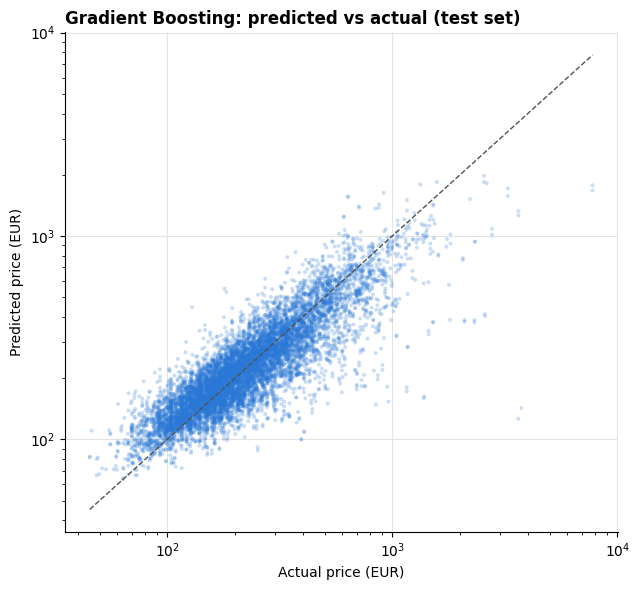

In [6]:
best_name = results["R2_log"].idxmax()
best = fitted[best_name]
pred_eur = np.exp(best.predict(X_test))
true_eur = np.exp(y_test)
print("Best model:", best_name)

fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(true_eur, pred_eur, s=8, alpha=0.25, color=BLUE, edgecolors="none")
lims = [true_eur.min(), true_eur.max()]
ax.plot(lims, lims, "--", color=INK_2, linewidth=1)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("Actual price (EUR)"); ax.set_ylabel("Predicted price (EUR)")
ax.set_title(f"{best_name}: predicted vs actual (test set)")
plt.tight_layout(); plt.show()

### Error per city
A model can look good overall but be weak in some cities.

In [7]:
per_city = pd.DataFrame({"city": X_test["city"].values, "true": true_eur.values, "pred": pred_eur})
per_city["abs_pct_error"] = (per_city["true"] - per_city["pred"]).abs() / per_city["true"] * 100
city_err = per_city.groupby("city").agg(
    listings=("true", "size"),
    median_price=("true", "median"),
    MAPE_pct=("abs_pct_error", "mean"),
    R2=("true", lambda s: r2_score(s, per_city.loc[s.index, "pred"])),
).sort_values("MAPE_pct").round(2)
city_err

,listings,median_price,MAPE_pct,R2
city,,,,
Lisbon,1181,224.44,18.41,0.59
Rome,1824,189.25,19.99,0.50
Athens,1030,129.82,21.42,0.46
Vienna,696,196.81,22.57,0.50
Paris,1314,336.01,22.72,0.57
Amsterdam,372,489.30,22.99,0.55
London,1982,266.47,23.82,0.49
Budapest,825,156.51,23.95,0.04
Barcelona,571,205.97,24.37,0.61


### Which features matter?
**Permutation importance:** shuffle one feature's values in the test set and measure how much the R² drops.
A big drop means the model relies on that feature. It works for any model, so it is easy to compare.

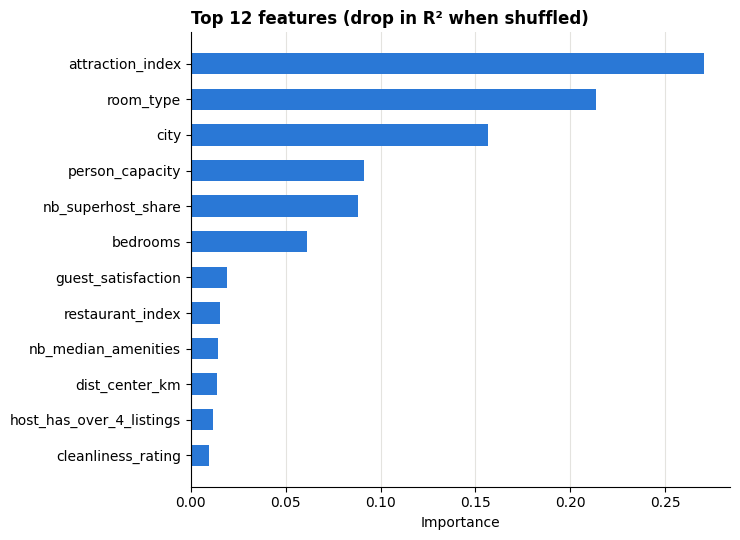

attraction_index            0.2707
room_type                   0.2135
city                        0.1569
person_capacity             0.0915
nb_superhost_share          0.0879
bedrooms                    0.0613
guest_satisfaction          0.0190
restaurant_index            0.0155
nb_median_amenities         0.0141
dist_center_km              0.0138
host_has_over_4_listings    0.0119
cleanliness_rating          0.0095
dtype: float64

In [8]:
perm = permutation_importance(best, X_test, y_test, n_repeats=5, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=X_test.columns).sort_values()
top = importance.tail(12)

fig, ax = plt.subplots(figsize=(7.5, 5.5))
ax.barh(top.index, top.values, color=BLUE, height=0.6)
ax.set_title("Top 12 features (drop in R² when shuffled)")
ax.set_xlabel("Importance")
ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

importance.sort_values(ascending=False).round(4).head(12)

**Finding:** The most important features are **attraction_index** (closeness to attractions), **room_type**, **city**, **person_capacity**,
**nb_superhost_share** and **bedrooms**. This matches the EDA: location, room type, city and size set the price.
Guest satisfaction is far down the list, again confirming that ratings barely affect price.
The neighbourhood feature `nb_superhost_share` from the scraped Inside Airbnb data ranks 5th, so the web-scraping enrichment did help the model.

## Step 5b: Price tier classification (Budget / Mid-range / Premium)

Predicting the exact price is hard. A useful business question is simpler: **is this listing cheap, average or expensive for its city?**

- Each city's prices are split into thirds **using the training data only** (so the test set does not leak into the thresholds).
- **Budget** = cheapest third of the city, **Mid-range** = middle third, **Premium** = most expensive third.
- The three classes are balanced, so random guessing would score about **33% accuracy**.

This turns the problem into **classification**, which is evaluated with a classification report and a confusion matrix.

In [9]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, classification_report, confusion_matrix

TIERS = ["Budget", "Mid-range", "Premium"]
price = data[TARGET]
train_q = price.iloc[train_idx].groupby(data["city"].iloc[train_idx]).quantile([1/3, 2/3]).unstack()
low, high = data["city"].map(train_q[1/3]), data["city"].map(train_q[2/3])
tier = pd.Series(np.select([price <= low, price <= high], TIERS[:2], TIERS[2]), index=data.index)

X_cls = data[CATEGORICAL + NUMERIC + ["latitude", "longitude"]].copy()
for col in CATEGORICAL:
    X_cls[col] = X_cls[col].astype("category")

clf = HistGradientBoostingClassifier(categorical_features="from_dtype", max_iter=500,
                                     learning_rate=0.05, random_state=RANDOM_STATE)
clf.fit(X_cls.iloc[train_idx], tier.iloc[train_idx])
tier_pred = clf.predict(X_cls.iloc[test_idx])
tier_true = tier.iloc[test_idx]

print(classification_report(tier_true, tier_pred, labels=TIERS))

              precision    recall  f1-score   support

      Budget       0.72      0.76      0.74      3386
   Mid-range       0.55      0.55      0.55      3338
     Premium       0.76      0.72      0.74      3568

    accuracy                           0.68     10292
   macro avg       0.67      0.67      0.67     10292
weighted avg       0.68      0.68      0.68     10292



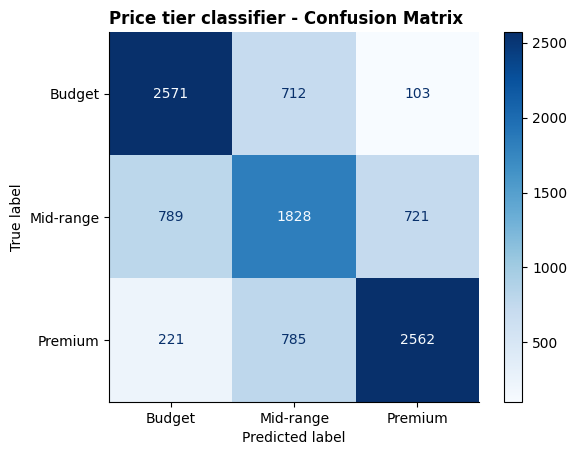

Budget <-> Premium mistakes: 324 of 10292 (3.1%)


In [10]:
cm = confusion_matrix(tier_true, tier_pred, labels=TIERS)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=TIERS)
disp.plot(cmap="Blues", values_format="d")
plt.title("Price tier classifier - Confusion Matrix")
plt.grid(False)
plt.show()

serious = cm[0, 2] + cm[2, 0]
print(f"Budget <-> Premium mistakes: {serious} of {cm.sum()} ({serious / cm.sum() * 100:.1f}%)")

### Simpler version: above or below the city median (2 classes)

              precision    recall  f1-score   support

Above median       0.83      0.80      0.81      5294
Below median       0.80      0.83      0.81      4998

    accuracy                           0.81     10292
   macro avg       0.81      0.81      0.81     10292
weighted avg       0.81      0.81      0.81     10292



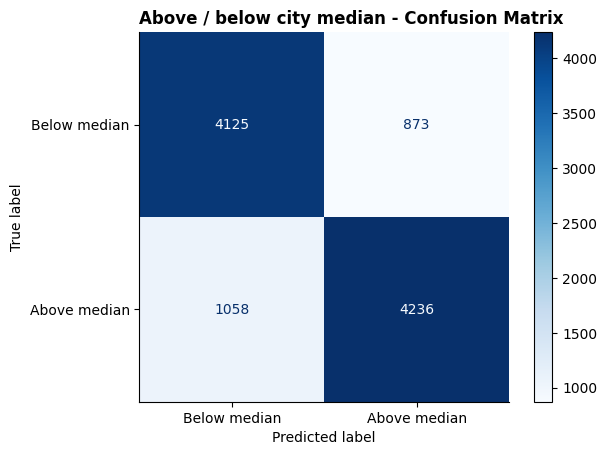

In [11]:
train_median = price.iloc[train_idx].groupby(data["city"].iloc[train_idx]).median()
above = pd.Series(np.where(price > data["city"].map(train_median), "Above median", "Below median"), index=data.index)

clf2 = HistGradientBoostingClassifier(categorical_features="from_dtype", max_iter=500,
                                      learning_rate=0.05, random_state=RANDOM_STATE)
clf2.fit(X_cls.iloc[train_idx], above.iloc[train_idx])
above_pred = clf2.predict(X_cls.iloc[test_idx])
print(classification_report(above.iloc[test_idx], above_pred))

ConfusionMatrixDisplay(confusion_matrix(above.iloc[test_idx], above_pred, labels=["Below median", "Above median"]),
                       display_labels=["Below median", "Above median"]).plot(cmap="Blues", values_format="d")
plt.title("Above / below city median - Confusion Matrix")
plt.grid(False)
plt.show()

**Finding:** The 3-tier classifier reaches **68% accuracy** (random guessing: 33%).
Budget and Premium are recognised well (F1 0.74 each); **Mid-range is the hardest** (F1 0.55) because it sits between the other two, and most of its errors go to a neighbouring tier.
Serious mistakes (Budget predicted as Premium or the reverse) are only **3.1%** of the test listings.
The simpler question, **above or below the city median**, is answered correctly **81%** of the time (precision and recall about 0.80 for both classes).

## Step 6: Try the model on an example listing

In [12]:
example = X_test.iloc[[0]].copy()
print(example[["city", "room_type", "day_type", "person_capacity", "bedrooms", "dist_center_km"]].to_string(index=False))
print(f"\nPredicted price: EUR {np.exp(best.predict(example))[0]:.0f}")
print(f"Actual price:    EUR {np.exp(y_test.iloc[0]):.0f}")

     city    room_type day_type  person_capacity  bedrooms  dist_center_km
Amsterdam Private room weekdays                2         1        0.544738

Predicted price: EUR 432
Actual price:    EUR 486


## Step 7: Save the model
The whole pipeline (encoding + scaling + model) is saved in one file, so it can be loaded later and used directly on raw rows.

In [13]:
from pathlib import Path
Path("../models").mkdir(exist_ok=True)
joblib.dump(best, "../models/price_model.joblib")
results.to_csv("../models/model_comparison.csv")
print("Saved ../models/price_model.joblib")

Saved ../models/price_model.joblib


## Conclusions
1. **Regression:** Gradient Boosting predicts listing prices with **R² 0.74 (log scale)**; half of the predictions are within **17.6%** of the real price.
2. **Classification:** the model places listings in the right **price tier (Budget / Mid-range / Premium) 68%** of the time (vs 33% by chance), and tells whether a listing is **above or below its city median 81%** of the time.
3. **Location (attractions), room type, city and size** drive the predictions; guest ratings matter little. The scraped neighbourhood feature `nb_superhost_share` ranks 5th, so the enrichment helped.
4. The evaluation is honest: weekday and weekend copies of the same apartment never appear in both training and test data.
5. **Limits and next steps:** the data has no reviews, photos or amenities per listing, which caps accuracy. Next: per-city models, hyperparameter tuning, and listing-level features.